# EDA: RuReviews

90 тыс. отзывов на женскую одежду с крупного маркетплейса. Метки проставлены автоматически по звёздам, которые поставил покупатель (1–2 → negative, 3 → neutral, 4–5 → positive), поэтому метки шумные.

In [1]:
import sys; sys.path.append('..')
import pandas as pd, matplotlib.pyplot as plt
from src.data import RAW, normalize
plt.rcParams['figure.figsize'] = (10, 4)
df = pd.read_csv(RAW, sep='\t')
print(df.shape)
df.sentiment.value_counts()

(90000, 2)


sentiment
negative    30000
neautral    30000
positive    30000
Name: count, dtype: int64

Классы идеально сбалансированы (авторы так собрали), и в названии класса опечатка: `neautral`.

In [2]:
df.sample(8, random_state=7)

,review,sentiment
45244,"Брюки хорошие, качество понравилось, но размер...",neautral
71932,Получила сегодня свой заказ - светло-серый ш...,positive
75416,"платье хорошее, второй раз заказываю для подруги",positive
47744,большое.. и очень яркое!! ! не подходит описан...,neautral
55705,"Качество пижамы хорошее,но вот с размерами бед...",neautral
26294,"Товар так и не пришёл спустя 2.5 месяца, прода...",negative
34385,"Очень узкие рукава в плечах, рука еле пролазит.",neautral
58336,"Не лучшая покупка. Я огорчена, подклад тянет, ...",neautral


## Длина отзывов

             count  mean   std  min  25%   50%   75%    max
sentiment                                                  
neautral   30000.0  19.6  19.9  1.0  7.0  13.0  25.0  193.0
negative   30000.0  22.5  22.1  1.0  9.0  15.0  28.0  192.0
positive   30000.0  18.0  17.0  0.0  7.0  13.0  23.0  174.0


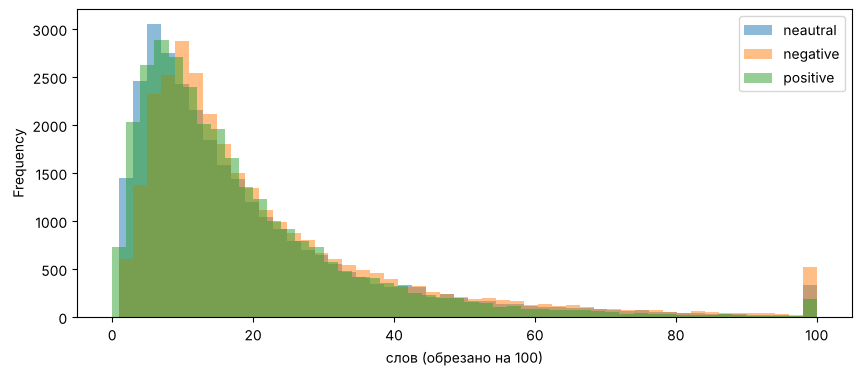

In [3]:
df['n_words'] = df.review.str.split().str.len()
print(df.groupby('sentiment').n_words.describe().round(1))
for s, g in df.groupby('sentiment'):
    g.n_words.clip(upper=100).plot.hist(bins=50, alpha=0.5, label=s)
plt.legend(); plt.xlabel('слов (обрезано на 100)'); plt.show()

Негативные и нейтральные отзывы длиннее: когда всё хорошо, люди пишут «отлично, рекомендую», а когда плохо, объясняют, что именно не так.

## Дубликаты и противоречия

In [4]:
df['norm'] = df.review.map(normalize)
g = df.groupby('norm').sentiment.agg(['nunique', 'size'])
print('строк:', len(df), '| уникальных текстов:', len(g))
print('текстов с разными метками:', (g['nunique'] > 1).sum())
g[g['nunique'] > 1].sort_values('size', ascending=False).head(10)

строк: 90000 | уникальных текстов: 86323
текстов с разными метками: 367


,nunique,size
norm,,
товар не пришел,3,184
"товар не пришел, деньги вернули",3,143
отлично,2,59
не пришло,2,49
товар не пришел. деньги вернули.,3,49
.,3,47
ок,2,43
качество не очень,3,41
мало,2,40


In [5]:
df[df.norm == 'товар не пришел'].sentiment.value_counts()

sentiment
negative    137
neautral     46
positive      1
Name: count, dtype: int64

«Товар не пришёл» есть во всех трёх классах: кто-то ставит 1 звезду из-за злости, кто-то 3, а кто-то 5, потому что продавец вернул деньги. По тексту такие случаи не различить, это потолок качества для любой модели. Ещё одна ловушка: если не убрать дубликаты до разбиения, одинаковые тексты попадут и в train, и в test, и метрика окажется завышенной.

## Шум в метках

In [6]:
import re
# \b в pandas со строками на pyarrow работает только для латиницы, поэтому границы слова вручную
pos_words = r'(?:^|[^а-я])(?:отличн|супер|рекоменд|довольн|прекрасн)'  # без «недовольна»
s1 = df[(df.sentiment == 'negative') & df.norm.str.contains(pos_words) & ~df.norm.str.contains(r'(?:^|[^а-я])не(?:[^а-я]|$)')]
print('negative, но текст похож на позитив:', len(s1))
for t in s1.review.head(6): print('  -', t[:140])

negative, но текст похож на позитив: 157
  - все прекрасно,кофтой давольна,подошла по размеру,качество отличное. Быстрая доставка,спасибо продавцу. Рекомендую
  - упаковано хорошо и пришло довольно быстро , НО ....ужасный материал ,нитки торчат ,рукава короткие .Недовольна покупкой!!
  - юбка отличная но пришла с дыркой на фото видно, что очень расстроило(((


Так что берите на 3-4 размера больше
  - Все отлично. Соответствует размеру
  - Качество платья ужасное, размер s оказался велик. Посылка шла довольно долго.


Часть таких отзывов — явная ошибка разметки: человек хвалит товар и ставит 1 звезду (возможно, путает шкалу или оценивает доставку).

In [7]:
stars = df[df.norm.str.contains(r'звезд|звёзд')]
print('отзывов с упоминанием звёзд:', len(stars))
stars.groupby('sentiment').size()

отзывов с упоминанием звёзд: 1760


sentiment
neautral    794
negative    504
positive    462
dtype: int64

## Смешанные отзывы

Нейтральный класс — самый сложный: часто это «плюс + минус» в одном тексте.

In [8]:
mixed = df[(df.sentiment == 'neautral') & df.norm.str.contains(r'(?:^|[^а-я])но(?:[^а-я]|$)')]
print('нейтральных с «но»:', round(len(mixed) / (df.sentiment == 'neautral').sum(), 2))
print('позитивных с «но»:', round(df[(df.sentiment == 'positive')].norm.str.contains(r'(?:^|[^а-я])но(?:[^а-я]|$)').mean(), 2))
for t in mixed.review.sample(5, random_state=1): print('  -', t[:150])

нейтральных с «но»: 0.28
позитивных с «но»: 0.22
  - пришёл заказ быстро, но качеством не довольна. Вторая причина : на одной штанине пятно...похожее на жирное..., буду совсем разочарована если не отстир
  - Красивые. но очень тонкое и хрупкое кружево. где черная ленточка кружево порвалось и торчат нитки. очень жаль.
  - заказ так и не дошёл. но деньги вернули
  - качество подкладки - го...но, сильно магнитится и прилипает к телу
  - Сшит хорошо, но материал - голимая синтетика


«Но» встречается и в позитивных отзывах почти так же часто, поэтому одно слово ничего не решает. Важно, что стоит после «но» («красивое, но маломерит» против «долго шло, но платье супер»). Bag-of-words это видит только через биграммы.